# Task 2 – Machine Learning Model

## SWYNEX Technologies – Machine Learning Internship

**Project:** Titanic Survival Prediction

**Objective:** Train and evaluate two machine learning classification models and compare their performance.

**Models Used:**
1. Logistic Regression
2. Random Forest Classifier

**Dataset:** Titanic Dataset

In [9]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
# Load Titanic dataset

df = pd.read_csv(
    "https://raw.githubusercontent.com/hari-vasu-186/Swynex-Intern-/main/Task-2-ML-Model/data/Titanic-Dataset.csv"
)

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (891, 12)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare      

In [12]:
# Data Preprocessing

# Remove unnecessary columns
df = df.drop(
    columns=['PassengerId', 'Name', 'Ticket', 'Cabin']
)

# Fill missing Age with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked with mode
df['Embarked'] = df['Embarked'].fillna(
    df['Embarked'].mode()[0]
)

# Fill missing Fare with median
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

print("Missing values after preprocessing:")
print(df.isnull().sum())

print("\nPreprocessed dataset:")
display(df.head())

Missing values after preprocessing:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

Preprocessed dataset:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [13]:
# Encode categorical variables

# Convert Sex into numerical values
df['Sex'] = df['Sex'].map({
    'male': 0,
    'female': 1
})

# Convert Embarked into numerical columns
df = pd.get_dummies(
    df,
    columns=['Embarked'],
    dtype=int
)

print("Categorical encoding completed!")

display(df.head())

print("\nFinal dataset shape:", df.shape)

Categorical encoding completed!


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1



Final dataset shape: (891, 10)


In [14]:
# Separate features and target

X = df.drop('Survived', axis=1)
y = df['Survived']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget values:")
display(y.head())

Features shape: (891, 9)
Target shape: (891,)

Input features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,0
2,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,3,0,35.0,0,0,8.0500,0,0,1



Target values:


,Survived
0,0
1,1
2,1
3,1
4,0


In [15]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (712, 9)
Testing features: (179, 9)
Training target: (712,)
Testing target: (179,)


In [16]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed!
Scaled training shape: (712, 9)
Scaled testing shape: (179, 9)


In [17]:
# Train Logistic Regression Model

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

# Make predictions
log_predictions = log_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [18]:
# Evaluate Logistic Regression

log_accuracy = accuracy_score(y_test, log_predictions)
log_precision = precision_score(y_test, log_predictions)
log_recall = recall_score(y_test, log_predictions)
log_f1 = f1_score(y_test, log_predictions)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall:", round(log_recall, 4))
print("F1 Score:", round(log_f1, 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1 Score: 0.7244


In [19]:
# Train Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [20]:
# Evaluate Random Forest

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.8212
Precision: 0.8136
Recall: 0.6957
F1 Score: 0.75


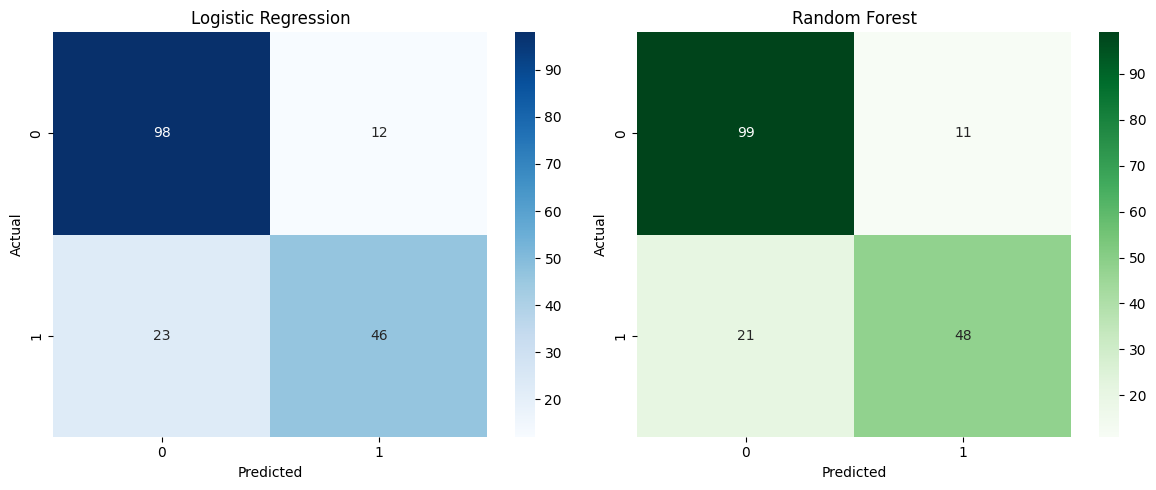

In [21]:
# Confusion Matrix for both models

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
cm_log = confusion_matrix(y_test, log_predictions)

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
cm_rf = confusion_matrix(y_test, rf_predictions)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [22]:
# Compare both machine learning models

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Logistic Regression': [
        log_accuracy,
        log_precision,
        log_recall,
        log_f1
    ],
    'Random Forest': [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8045,0.8212
1,Precision,0.7931,0.8136
2,Recall,0.6667,0.6957
3,F1 Score,0.7244,0.7500


# Conclusion

In this project, two machine learning classification algorithms, Logistic Regression and Random Forest Classifier, were trained using the Titanic dataset.

Both models were evaluated using accuracy, precision, recall and F1-score.

The results showed that Random Forest performed better than Logistic Regression across all four evaluation metrics.

- Logistic Regression achieved an accuracy of 80.45%.
- Random Forest achieved an accuracy of 82.12%.

Random Forest achieved better results because it combines multiple decision trees and can capture more complex relationships between passenger features and survival.

Therefore, Random Forest was the better-performing model in this experiment.

This project provided practical experience in data preprocessing, feature encoding, model training, prediction and performance evaluation using Python and Scikit-learn.